#### About

This file is used to make the predictions on all the splits for all 3 models. This predictions are saved in a seperate file to use for visualizations, to not recompute it all the time.

##### Data

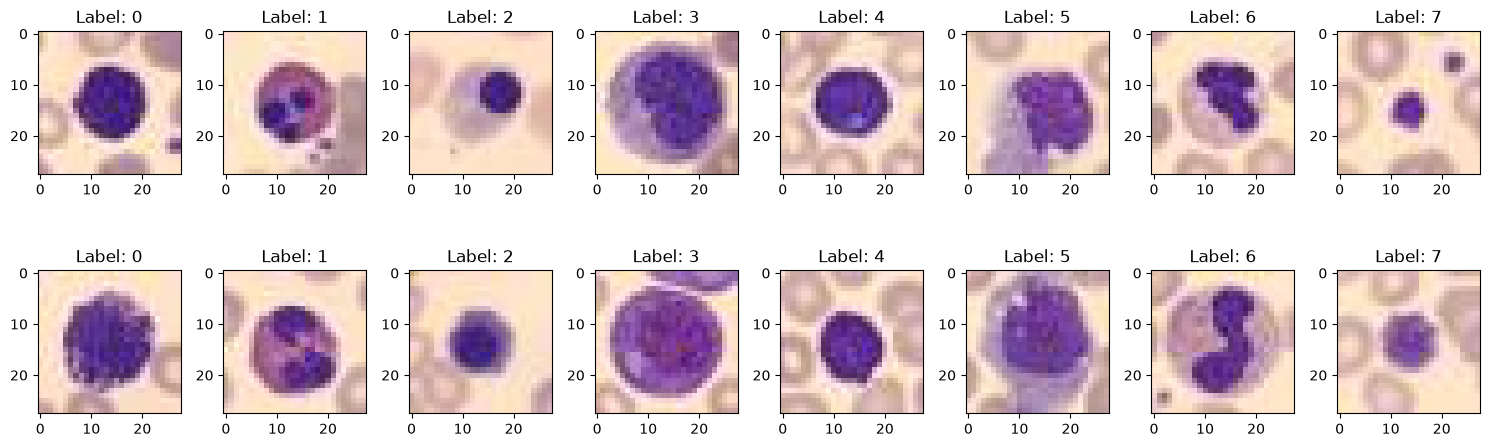

(11959, 28, 28, 3)


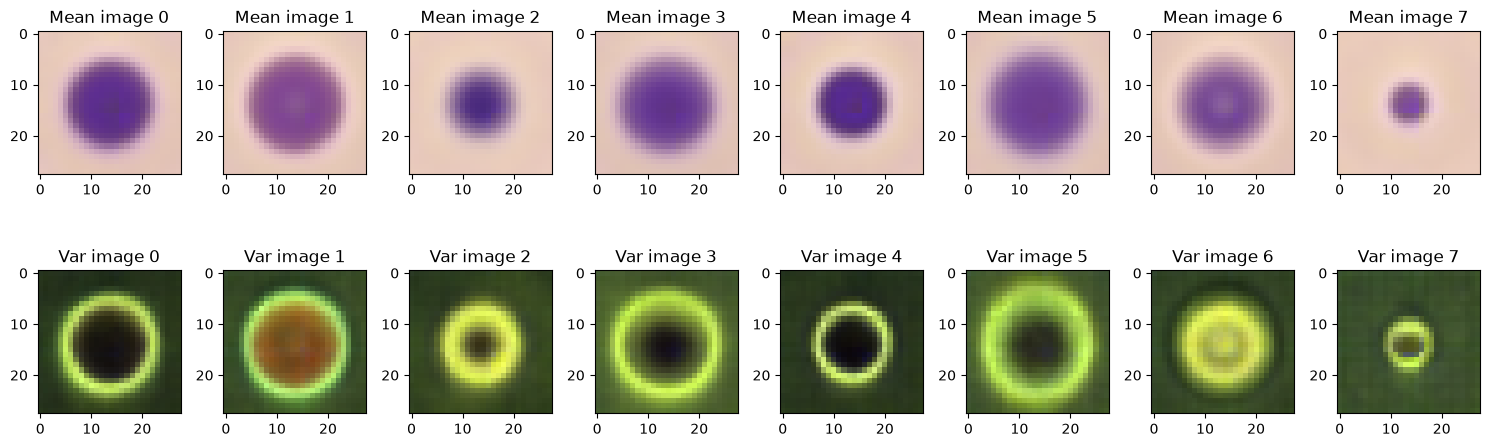

[244 624 311 579 243 284 666 470]


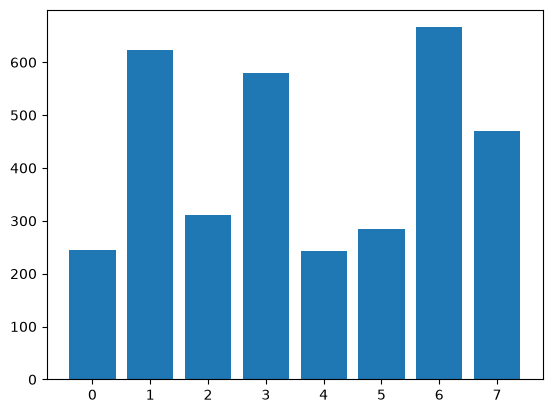

In [95]:
import numpy as np
import matplotlib.pyplot as plt

with np.load("../data/bloodmnist.npz", allow_pickle=False) as dataset:
    t_images = dataset["train_images"]
    t_labels = dataset["train_labels"].reshape(-1)
    test_images = dataset["test_images"]
    test_labels = dataset["test_labels"].reshape(-1)




fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(8): 
    class_img = t_images[t_labels==i]
    axes[0,i].imshow(class_img[0])
    axes[0,i].title.set_text(f"Label: {i}")
    axes[1,i].imshow(class_img[1])
    axes[1,i].title.set_text(f"Label: {i}")

plt.tight_layout()
plt.show()


print(t_images.shape)

fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(0,8):
    class_img = t_images[t_labels==i]
    mean_image = np.mean(class_img, axis=(0,), dtype=np.int64) 
    var_image = np.var(class_img, axis=(0,), dtype=np.int64) 
    var_image = var_image/np.max(var_image)
    axes[0,i].imshow(mean_image)
    axes[0,i].title.set_text(f"Mean image {i}")    
    axes[1,i].imshow(var_image)
    axes[1,i].title.set_text(f"Var image {i}")   

plt.tight_layout()
plt.show()

labels = np.bincount(test_labels)
print(labels)
axes= plt.bar(np.arange(0,8), labels)

plt.show()

[0.2664876  0.08916575]
(3421, 2) (11959,)


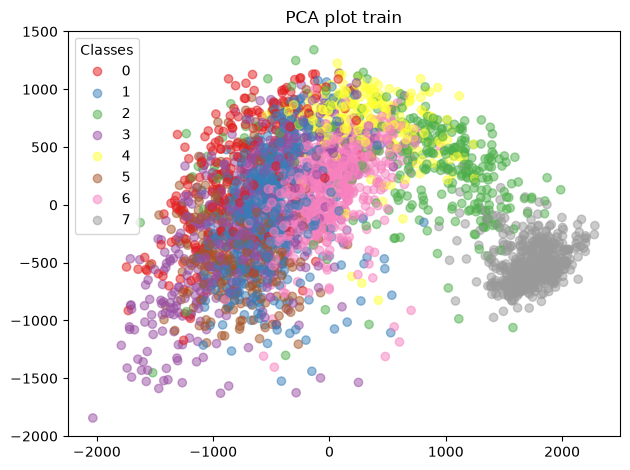

(3421, 2) (11959,)


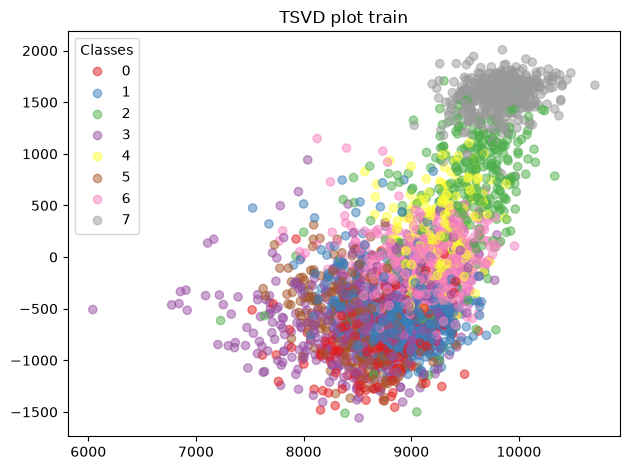

In [71]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD  

pca = PCA(n_components=2)
train_pca = pca.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(pca.explained_variance_ratio_)
print(train_pca.shape, t_labels.shape)
scatter=plt.scatter(train_pca[:,0], train_pca[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("PCA plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()

"""tsne = TSNE(n_components=2, perplexity=15)
train_tnse = tsne.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(train_tnse.shape, t_labels.shape)
scatter=plt.scatter(train_tnse[:,0], train_tnse[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("TSNE plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()"""

tsvd = TruncatedSVD(n_components=2)
train_tsvd = tsvd.fit_transform(test_images.reshape((test_images.shape[0], -1)))
print(train_tsvd.shape, t_labels.shape)
scatter=plt.scatter(train_tsvd[:,0], train_tsvd[:,1], c=test_labels, alpha=0.5, cmap="Set1")
plt.title("TSVD plot train")
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Classes")
plt.tight_layout()
plt.show()


#### Predictions

(3421, 9)
[318 626 289 551 233 256 675 473]


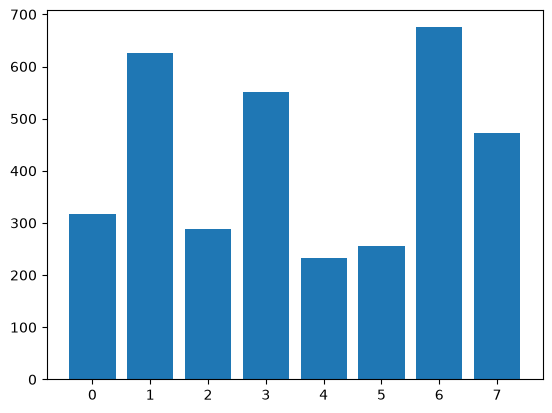

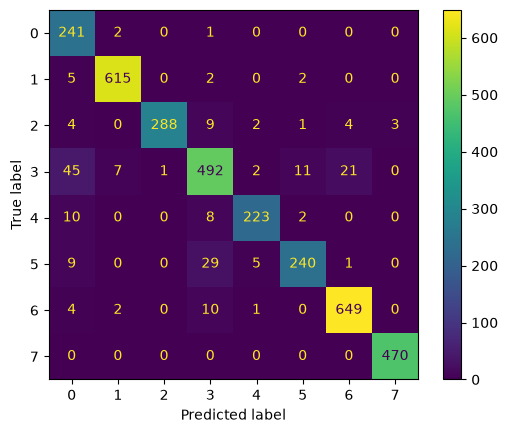

In [66]:
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_pred = pd.read_csv("../predictions/bloodmnist_test_[AUC]0.997_[ACC]0.941@resnet50_224_1.csv", header=None)
test_pred = test_pred.to_numpy()
print(test_pred.shape)
test_pred = np.argmax(test_pred[:,1:], axis=1)

labels = np.bincount(test_pred)
print(labels)
axes= plt.bar(np.arange(0,8), labels)

plt.show()

cm = confusion_matrix(test_labels, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()